# 1、基础知识

## 1.1 Deep Agents 与高阶提示词

两者的关系理解成：

+ Deep Agents 是智能体系统的组织架构，决定任务如何规划、分工、执行和反馈；
+ 高阶提示词是智能体系统的思考规范，决定模型如何分析问题、拆解逻辑和组织输出。

1）**Deep Agents 解决的是“任务怎么组织”的问题**。

面对复杂任务时，智能体不再只做一次性回答，而是要具备下面这些能力：

+ 先把复杂任务拆成可执行的子目标；
+ 为不同子目标匹配工具或子智能体；
+ 执行过程中观察中间结果，发现缺口后继续补充；
+ 根据工具返回和子任务结果调整计划；
+ 出现偏差时，通过反思和修正让任务继续向目标收敛

总结：**拆->分（分配Tool/Agents）->补（补充上下文、内容）->调整（调整相关计划）->核验（收敛后退出）**

2）**高阶提示词解决的是“模型应该怎么思考”的问题**。

高阶提示词会进一步告诉模型“按什么步骤思考”，例如：

``` text
请按以下流程分析：
1. 先提取评论中出现的具体问题；
2. 再判断情绪倾向，并给出理由；
3. 按影响程度对问题排序；
4. 每个问题给出可落地的改进建议；
5. 最后用一句话总结核心痛点。

```



真正决定系统稳定性的，往往是这两件事能不能配合好：**用 DeepAgents 组织执行链路，用高阶提示词约束推理过程。**

## 1.2 三类框架使用场景

这三个框架都在 LangChain 生态里，但使用场景并不完全一样。

| 框架        | 核心定位                                                                 | 更适合什么时候使用                                                                 |
|-------------|--------------------------------------------------------------------------|-----------------------------------------------------------------------------------|
| LangChain   | 基础开发框架，封装模型、Prompt、工具、Agent 等能力                        | 快速构建简单 Agent，或者自己组合模型与工具                                          |
| LangGraph   | 图执行框架，强调状态、节点、分支、持久化和流式输出                        | 流程明确、需要细粒度控制、需要稳定编排的复杂工作流                                  |
| DeepAgents  | 深度智能体框架，强调自主规划、子智能体、上下文管理和长期记忆              | 长任务、多步骤、多角色、需要智能体自己规划和调度的任务                              |

工程化的说法：

+ 如果你只是想**让模型调用几个工具**，LangChain Agent 就够了。
+ 如果你已经知道业务流程每一步怎么走，**并希望强控制每个节点**，优先用 LangGraph。
+ 如果**任务非常开放，步骤不固定**，还需要智能体自己拆任务、调工具、分配子任务，就适合使用 DeepAgents




## 1.3 DeepAgents 最核心能力

| 核心能力              | 解决问题                                                       | 可以怎么理解                                                       |
|-----------------------|----------------------------------------------------------------|--------------------------------------------------------------------|
| **智能规划与任务分解**    | 复杂任务不知道从哪开始、做完哪些步骤才算完成                    | 先拆任务、再执行、再更新进度                                        |
| **高效上下文管理**        | 搜索结果、文件内容、工具返回值太大，容易塞爆上下文              | 把大块信息写到文件系统，需要时再读回来                              |
| **子智能体机制**          | 主智能体既要规划又要干活，专业性和上下文都会被稀释              | 主智能体负责调度，子智能体负责专业子任务                            |
| **长期记忆**              | 多轮会话之间容易失忆，历史经验无法复用                          | 把关键记忆保存下来，后续会话可继续读取                              |

## 1.4 两类多智能体架构

### 1.4.1 层级模式
层级模式，也叫指挥官模式，核心逻辑是：**一个主智能体负责调度，多个子智能体负责执行**。

它的流程通常是：

1. 用户输入一个复杂任务；
2. 主智能体理解目标，并拆成多个子任务；
3. 主智能体把子任务分给不同的专业子智能体；
4. 子智能体在自己的上下文里完成局部任务；
5. 子智能体把结果返回给主智能体；
6. 主智能体汇总、判断、整理成最终结果。

优缺点分析
+ **优点**: 路线清楚、责任明确，比较适合工程项目落地。
+ **缺点**：主智能体非常关键。如果主智能体一开始理解错了目标，或者分配错了子任务，后面的执行就会跟着偏。另外，所有任务都要经过主智能体调度，任务特别复杂时，主智能体也可能成为瓶颈。

它强调的是：**主智能体负责规划和调度，子智能体负责专业执行。**

### 1.4.2 协作模式
协作模式，也叫网状模式。

协作模式（Collaborative Network）的核心逻辑是：多个智能体围绕同一个问题共享信息、互相补充、共同推进。

它更像多位专家开会。每个 Agent 都可以根据自己的角色和上下文发表意见，也可以根据其他 Agent 的输出继续补充、质疑或修正。这里不一定有一个绝对的“领导”，系统更依赖 Agent 之间的互动来让结果逐步收敛。

优缺点分析：
+ **优点**：灵活，适合开放式探索、方案讨论、观点碰撞。比如多个专家一起评估一个商业方案、讨论一个技术路线，协作模式可能产生更多角度。
+ **缺点**：更容易失控。多个 Agent 可能不断补充、反驳、再补充，最后讨论很久却没有明确结论。调试时也更麻烦，因为你很难快速判断：最终答案到底是哪个 Agent 的判断影响最大。


## 1.5 常见多智能体框架

DeepAgents 更像层级/指挥官模式：主智能体先规划，再把任务分派给子智能体，最后统一汇总结果。

AutoGen 更像去中心化/网状协作模式：多个 Agent 像在一个群聊里讨论问题，根据上下文自由接话、互相补充。

CrewAI 更像角色和任务流程驱动的团队协作：**开发者通常会先定义角色、任务和流程，再让不同 Agent 按设定完成各自职责**。它可以做层级式流程，也可以做更灵活的角色协作。

| 框架        | 更像什么                        | 主要组织方式    | Agent 之间怎么协作                                                                   | 更适合的任务                                    | 主要风险                                                                 |
|-------------|--------------------------------|----------------|--------------------------------------------------------------------------------------|------------------------------------------------|--------------------------------------------------------------------------|
| DeepAgents  | 项目负责人带多个专业助手        | 层级调度        | 主智能体通过 task 等机制分派任务，子智能体完成后返回结果                               | 深度研究、长任务、报告生成、多步骤资料整理        | 主智能体判断质量很关键，拆错任务会影响后续结果                             |
| AutoGen     | 多个专家在群里讨论              | 网状协作        | 多个 Agent 围绕上下文自由对话、互相补充、互相修正                                     | 头脑风暴、方案讨论、开放式探索、复杂问题求解        | 容易发散，调试时难追踪关键判断来自哪里                                     |
| CrewAI      | 预设好的团队按任务流程协作      | 角色 + 任务流程 | 先定义角色、目标和任务，再让 Agent 按流程协作                                         | 标准业务流程、多角色执行、较清晰的团队分工          | 效果依赖角色和任务设计，流程设计不好时容易僵硬                             |




# 1.6 子智能体设计小清单

| 检查项         | 问自己一句话                                 |
|----------------|----------------------------------------------|
| 职责是否单一   | 它是不是只负责一类清晰任务？                 |
| 描述是否清楚   | 主智能体看完description后知道什么时候叫它吗？|
| 工具是否够少   | 它是不是只拿到了必须使用的工具？             |
| 输出是否好用   | 它返回的是结论，还是一堆未经整理的过程信息？ |
| 成本是否值得   | 这个任务真的值得多调用一次智能体吗？         |
| 日志是否可查   | 出错时能不能看出它接了什么任务、做了什么？   |

# 2、项目要解决什么问题

## 2.1 普通问答为什么不够

普通大模型问答的链路很简单：用户提问 -> 模型根据已有知识回答

这种方式适合常识问答、文本改写、简单总结。

但企业里的“搜索”和“研究”通常没有这么简单，**因为很多信息不在模型参数里**。

比如：

+ 公司数据库里的药品信息、销售数据、库存数据；
+ 企业内部制度、产品说明、培训文档；
+ 最新新闻、政策、网页资料；
+ 用户这次临时上传的文件；
+ 最终还要生成 Markdown 或 PDF 报告。

如果只靠模型自己回答，它很容易遇到两个问题：不知道最新信息，或者编出看似合理但没有依据的内容。

所以这个项目要做的不是“让模型多想一会儿”，而是让**模型有能力去不同地方查资料**。

## 2.2 “深度”到底深在哪里
这里的“深度”，不是界面更复杂，也不是提示词写得更长，**而是信息来源更多，查找过程可以反复迭代**。

| 信息来源         | 适合解决什么问题                                               | 在项目中的承接方式                                    |
|------------------|----------------------------------------------------------------|------------------------------------------------------|
| 模型自身知识     | 通用知识、简单解释、已有常识                                   | 主智能体直接回答或参与综合分析                        |
| 网络搜索         | 最新公开资料、网页内容、外部信息                               | 网络搜索助手，底层使用 TAVILY                         |
| 数据库           | 企业业务数据，如药品表、销售表                                 | 数据库查询助手，负责查表、查结构、执行 SQL            |
| RAG 知识库       | 企业内部文档、制度、私有知识库                                 | RAGFlow 助手，负责和知识库助手交互                    |
| 上传文件         | 用户本次上传的 PDF、Word、Excel、文本等                       | 主智能体通过文件读取工具读取                          |

这里有两个容易混的点：

+ 模型不是一个子智能体。它是**主智能体和子智能体共同使用**的基础能力。
+ 上传文件也不是一个子智能体。它更像主智能体手里的一个工具，用来读取本次会话中的材料。

## 2.3 案例流程
举个例子，用户问：
```text
从数据库中查询药品信息，并生成 PDF 文件。
```

这句话背后可能会发生下面这些动作：

1. 主智能体判断这是一个数据库查询任务，而且最终要生成文件。
2. 主智能体调用数据库查询助手。
3. 数据库助手先看有哪些表，再看药品表结构和数据预览。
4. 数据库助手执行合适的 SQL，返回药品信息。
5. 主智能体把结果整理成 Markdown。
6. 主智能体再调用 Markdown 转 PDF 工具。
7. 前端持续显示“正在查表、正在生成 Markdown、正在转 PDF”等进度。

这就是「深度研搜」和一次普通问答的区别：它不是只回答一句话，而是围绕目标组织一串可观察、可复用的任务步骤。

# 3、整体架构：一主三从

## 3.1 主智能体负责统筹
项目采用 DeepAgents 很典型的**层级式多智能体架构**，也就是前面讲过的 Orchestrator-Workers 模式。

主智能体像团队负责人，负责：

+ 理解用户到底想要什么；
+ 拆分任务，判断需要哪些资料；
+ 决定是否调用网络搜索助手；
+ 决定是否调用数据库查询助手；
+ 决定是否调用 RAGFlow 助手；
+ 必要时读取上传文件；
+ 汇总结果，生成最终回答、Markdown 或 PDF。

主智能体不应该把所有事情都自己做完。
+ 主智能体越像“什么都亲自干的人”，整个系统越难维护；
+ 它越像“会分配任务的负责人”，项目结构越清楚。

## 3.2 三个专家子智能体

本项目规划的 3 个子智能体：

| 子智能体         | 负责内容                                                         | 典型工具                                   |
|------------------|------------------------------------------------------------------|--------------------------------------------|
| **网络搜索助手**    | 查询公开网络资料，适合最新信息、公开网页、外部知识               | TAVILY 搜索工具                            |
| **数据库查询助手**   | 查询企业业务数据库，读取表名、表结构、数据预览并执行 SQL         | 查表、查结构、执行 SQL                     |
| **RAGFlow 助手**     | 查询企业内部知识库，先获取可用助手，再向知识库提问               | 创建会话、向知识库提问                     |

## 3.3 项目架构总结（四个Agent，9个Tool）
可以把整个项目记成一句话：4 个智能体，9 个工具。

1） 4个智能体
| 类型     | 名称               | 作用                                             |
|----------|--------------------|--------------------------------------------------|
| 主智能体 | Main Agent         | 理解任务、规划步骤、调度助手、汇总结果、生成交付物 |
| 子智能体 | 网络搜索助手       | 查询公开网络资料                                 |
| 子智能体 | 数据库查询助手     | 查询业务数据库                                   |
| 子智能体 | RAGFlow 助手       | 查询企业内部知识库                               |

2）9个工具划分
| **归属**               | 工具数量 | **工具内容**                                       |
|--------------------|----------|------------------------------------------------|
| 主智能体           | 3个      | 读取上传文件、生成 Markdown、Markdown 转 PDF   |
| 网络搜索助手       | 1个      | TAVILY 网络搜索                                |
| 数据库查询助手     | 3个      | 获取表名、获取表结构和数据预览、执行 SQL       |
| RAGFlow 助手       | 2个      | 获取可用助手或会话、向知识库助手提问           |

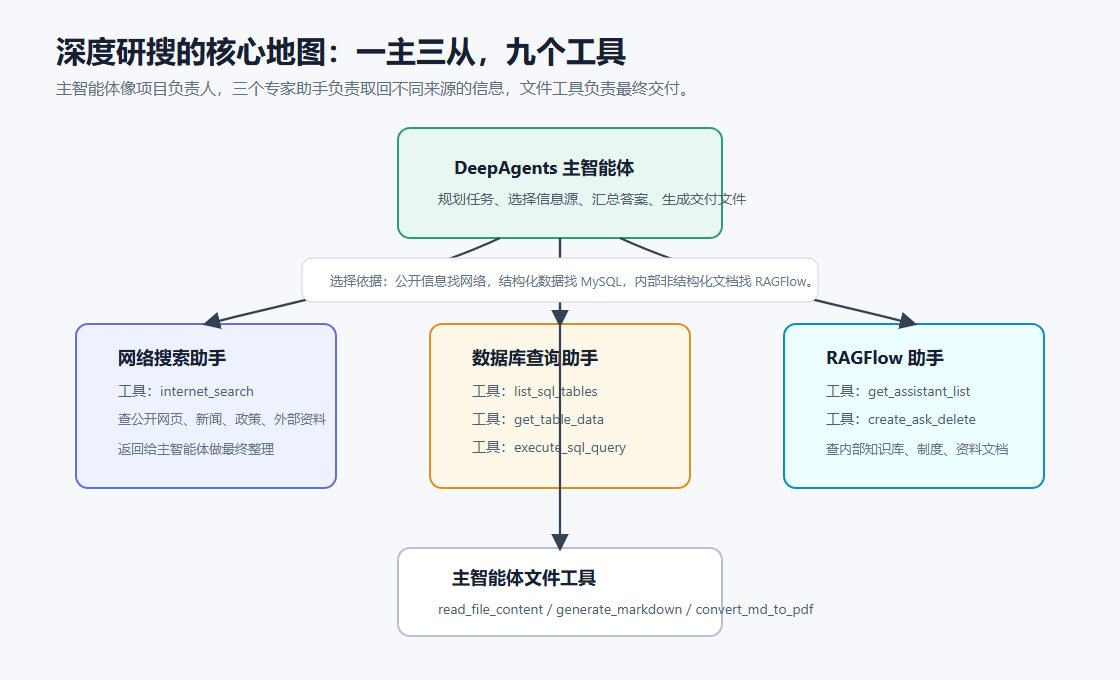

## 3.4 技术栈速览
| 层次         | 技术                                           | 在项目中的作用                                                       |
|--------------|------------------------------------------------|----------------------------------------------------------------------|
| 智能体框架   | DeepAgents、LangChain、LangGraph、langchain-core | 组织主智能体、子智能体、工具调用和思考循环                           |
| 模型接口     | OpenAI兼容接口、init_chat_model                | 统一创建大模型对象，供所有智能体使用                                 |
| Web服务      | FastAPI、Uvicorn                               | 提供任务提交、文件上传、下载等后端接口                               |
| 实时通信     | WebSocket                                      | 将Agent执行过程实时推送给前端                                        |
| 参数校验     | Pydantic、typing-extensions                    | 定义请求参数、状态结构或工具入参，并提供类型兼容能力                 |
| 网络搜索     | TavilySearchAPI                                | 查询互联网公开信息，并返回结构化搜索结果                             |
| 私有知识库   | RAGFlow、ragflow_sdk                          | 连接企业内部知识库，查询私有文档内容                                 |
| 数据库       | MySQL、mysql-connector-python                  | 查询业务数据、表结构和SQL结果                                        |
| 文件处理     | FileIO、python-docx、pypdf、pandas、ReportLab  | 生成报告、读取上传文件或解析文档内容                                 |
| 环境配置     | python-dotenv                                  | 从.env读取模型、搜索、数据库和RAGFlow连接配置                        |
| HTTP请求     | requests                                       | 做外部服务连通性检查，或在需要时直接访问HTTP接口                     |
| 异步执行     | asyncio、ContextVar                            | 支持并发请求隔离和跨步骤传递上下文                                   |
| 路径管理     | pathlib、shutil                                | 处理路径拼接、文件移动、上传文件归档                                 |